# Supplemental Figure 5, Panel A

MA plots showing differential accessibility due to IFNg and Dex at 1h and 6h of treatment

*Output: PanelA.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(ggrastr)
library(patchwork)
library(RColorBrewer)
library(here)
here::i_am("figures/SuppFig5/PanelA/PanelA_MA.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig5/PanelA

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         RColorBrewer_1.1-3 patchwork_1.3.0    ggrastr_1.0.2     
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4       
 [9] purrr_1.0.2        readr_2.1.5        tidyr_1.3.1        tibble_3.2.1      
[13] ggplot2_3.5.2      tidyverse_2.0.0   

loaded 

# Load data

In [2]:
dar_IFN_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_1h.tsv"),
  sep = "\t"
)

dar_IFN_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_6h.tsv"),
  sep = "\t"
)

dar_Dex_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_1h.tsv"),
  sep = "\t"
)

dar_Dex_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_6h.tsv"),
  sep = "\t"
)

dar_IFN_1h %>% group_by(change) %>% summarize(n())
dar_IFN_6h %>% group_by(change) %>% summarize(n())
dar_Dex_1h %>% group_by(change) %>% summarize(n())
dar_Dex_6h %>% group_by(change) %>% summarize(n())

change,n()
<chr>,<int>
down,17
ns,111156
up,548


change,n()
<chr>,<int>
down,255
ns,109781
up,1685


change,n()
<chr>,<int>
down,407
ns,108217
up,3097


change,n()
<chr>,<int>
down,646
ns,108653
up,2422


# Generate plots

In [5]:

p1 <- dar_IFN_1h %>% ggplot(aes(x=logCPM, y=logFC, color=change)) + geom_hline(yintercept=0, linetype=2) + rasterize(geom_point(size=.5), dpi=300) + scale_color_manual(values=c("up"=brewer.pal(6, "Paired")[6], "ns" = "#cccccc", "down"=brewer.pal(3,"Paired")[2])) + 
    coord_cartesian(xlim=c(-4,8), ylim=c(-3,3)) + xlab("LogCPM Accessibility") + ylab("Log2 fold change, accessibility\nIFNy vs Veh") + scale_x_continuous(breaks=c(-4,0,4,8)) + scale_y_continuous(breaks=c(-3,0,3)) +
    ggtitle("IFNy 1h",subtitle="down: 17, up: 548")
p2 <- dar_Dex_1h %>% ggplot(aes(x=logCPM, y=logFC, color=change)) + geom_hline(yintercept=0, linetype=2) + rasterize(geom_point(size=.5), dpi=300) + scale_color_manual(values=c("up"=brewer.pal(6, "Paired")[6], "ns" = "#cccccc", "down"=brewer.pal(3,"Paired")[2])) + 
    coord_cartesian(xlim=c(-4,8), ylim=c(-3,3)) + xlab("LogCPM Accessibility") + ylab("Log2 fold change, accessibility\nDex vs Veh") + scale_x_continuous(breaks=c(-4,0,4,8)) + scale_y_continuous(breaks=c(-3,0,3)) +
    ggtitle("IFNy 6h",subtitle="down: 255, up: 1685")
p3 <- dar_IFN_6h %>% ggplot(aes(x=logCPM, y=logFC, color=change)) + geom_hline(yintercept=0, linetype=2) + rasterize(geom_point(size=.5), dpi=300) + scale_color_manual(values=c("up"=brewer.pal(6, "Paired")[6], "ns" = "#cccccc", "down"=brewer.pal(3,"Paired")[2])) + 
    coord_cartesian(xlim=c(-4,8), ylim=c(-3,3)) + xlab("LogCPM Accessibility") + ylab("Log2 fold change, accessibility\nIFNy vs Veh") + scale_x_continuous(breaks=c(-4,0,4,8)) + scale_y_continuous(breaks=c(-3,0,3)) +
    ggtitle("Dex 1h",subtitle="down: 407, up: 3097")
p4 <- dar_Dex_6h %>% ggplot(aes(x=logCPM, y=logFC, color=change)) + geom_hline(yintercept=0, linetype=2) + rasterize(geom_point(size=.5), dpi=300) + scale_color_manual(values=c("up"=brewer.pal(6, "Paired")[6], "ns" = "#cccccc", "down"=brewer.pal(3,"Paired")[2])) + 
    coord_cartesian(xlim=c(-4,8), ylim=c(-3,3)) + xlab("LogCPM Accessibility") + ylab("Log2 fold change, accessibility\nDex vs Veh") + scale_x_continuous(breaks=c(-4,0,4,8)) + scale_y_continuous(breaks=c(-3,0,3)) +
    ggtitle("Dex 6h",subtitle="down: 646, up: 2422")

# Assemble figure panel

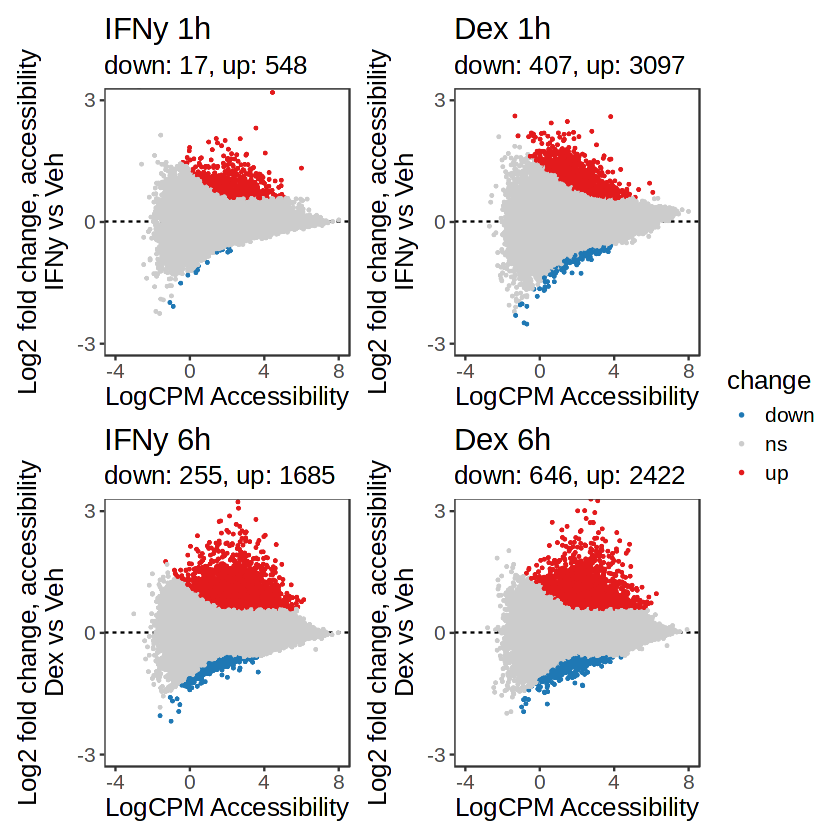

In [6]:
((p1 / p2) | (p3 / p4)) + plot_layout(guides="collect")
ggsave("PanelA.pdf", width=8, height=8)